# Trouver les paires cointégrées

In [1]:
import csv
import os
import yfinance as yf
import numpy as np
from test_coint import Coint_verif, CointError
import warnings
import pandas as pd
from fit_ou_model import OUEstimator
from test_coint import Coint_verif
import matplotlib.pyplot as plt

warnings.filterwarnings(
    "ignore",
    message="Casting complex values to real discards the imaginary part"
)

warnings.filterwarnings("ignore", category=UserWarning, message=".*interpolation.*")
warnings.filterwarnings("ignore", message=".*p-values available in the look-up table.*")

## Récupérer les données historiques

In [2]:
DATA_FILE = "financial_datas.csv"


def save_data(df: pd.DataFrame, path: str = DATA_FILE):
    df.to_csv(path)


def load_data(path: str = DATA_FILE) -> pd.DataFrame:
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    return df


ticker = set()
pairs = list()

with open("pairs_universe.csv", "r", encoding="utf-8") as fichier:
    lecteur = csv.reader(fichier)
    i = 0
    for ligne in lecteur:
        if i != 0 :
            premiere_colonne = ligne[0]
            deuxieme_colonne = ligne[1]
            ticker.add(premiere_colonne)
            ticker.add(deuxieme_colonne)
            pairs.append((premiere_colonne, deuxieme_colonne))
        i += 1

if os.path.exists(DATA_FILE):
    print("no need to download the data frome yfinance")
    data = load_data()
else:
    print("downloading the data ...")
    big_str = ''
    for tickers in ticker:
        big_str += tickers + ' '
    data = yf.download(big_str, start='2010-01-01', end="2024-01-01")['Close']
    save_data(data)

no need to download the data frome yfinance


## Faire les tests statistiques de cointégration

Ne pas la faire tourner à chaque utilisation, seulement lorsque on modifie les dates de récupération de données, car c'est long

In [ ]:
black_list = ['SIE', 'WBA', 'X', 'CMA', 'SQ', 'PXD', 'KAR'] # les actifs qui ne sont plus dispo sur yfinance.

coint_pairs = []

for x, y in pairs:
    if x in black_list or y in black_list :
        print("cette paire n'est pas dispo sur yfinance")
    else :
        df = pd.concat([data[x], data[y]], axis=1).dropna() # gérer les conflits de lignes manquantes dans l'un et potentiellement dans l'autre.

        prixA = df.iloc[:, 0]
        prixB = df.iloc[:, 1]

        try :
            test = Coint_verif(prixA, prixB)
            test.test_batterie()
            coint_pairs.append((x,y))
        except CointError as e:
            print(f"La paire {x}, {y} n'est pas bonne candidate : {e}")

print(f"Les paires mathématiquement cointégrés sont : {coint_pairs}") # -> [('UNH', 'ELV'), ('TMO', 'DHR'), ('ALL', 'TRV'), ('DE', 'AGCO'), ('SNPS', 'CDNS'), ('ADP', 'PAYX'), ('EMR', 'ROK'), ('VRSK', 'MCO')]

Faire tourner la cellule au dessus n'est pas nécessaire tout le temps, les paires cointégrés sont : 
- UNH - ELV
- TMO - DHR
- ALL - TRV
- DE - AGCO
- SNPS - CDNS
- ADP - PAYX
- EMR - ROK
- VRSK - MCO

## Test OU et demi vie.

In [6]:
paires = [('UNH', 'ELV'), ('TMO', 'DHR'), ('ALL', 'TRV'), ('DE', 'AGCO'), ('SNPS', 'CDNS'), ('ADP', 'PAYX'), ('EMR', 'ROK'), ('VRSK', 'MCO')]
for tik1, tik2 in paires :
    df = pd.concat([data[tik1], data[tik2]], axis=1).dropna()
    prixA = df.iloc[:, 0]
    prixB = df.iloc[:, 1]

    # Récupération du spread
    coint_obj = Coint_verif(prixA=prixA, prixB=prixB)
    spread, hedge = coint_obj.spread_n_hedge_ratio()

    # Fit du model OU
    fiter = OUEstimator(dt=1) # un jour
    fiter.fit_ols(spread)
    print(f"Pour la paire ({tik1, tik2}), la demie vie est de : {fiter.half_life}, donc un theta de {fiter.theta} | Le sigma (volatilité) : {fiter.sigma}")

Pour la paire (('UNH', 'ELV')), la demie vie est de : 55.10869538141493, donc un theta de 0.012577818722845413 | Le sigma (volatilité) : 2.7019215769926306
Pour la paire (('TMO', 'DHR')), la demie vie est de : 68.54483583582072, donc un theta de 0.01011231804858616 | Le sigma (volatilité) : 3.1124487269675627
Pour la paire (('ALL', 'TRV')), la demie vie est de : 76.07332018530437, donc un theta de 0.009111567352016871 | Le sigma (volatilité) : 0.9910671944868782
Pour la paire (('DE', 'AGCO')), la demie vie est de : 48.50208443746844, donc un theta de 0.014291080241171672 | Le sigma (volatilité) : 3.612510221561495
Pour la paire (('SNPS', 'CDNS')), la demie vie est de : 25.26456959316733, donc un theta de 0.02743554280645269 | Le sigma (volatilité) : 1.7152934202848333
Pour la paire (('ADP', 'PAYX')), la demie vie est de : 64.29584071827871, donc un theta de 0.010780591292010122 | Le sigma (volatilité) : 1.1376162135757428
Pour la paire (('EMR', 'ROK')), la demie vie est de : 79.9062441

Avec les paires disponibles, on ne garde que  :
- UNH - ELV : demie vie de 55 jours pour un $\sigma$ de 2.7
- TMO - DHR : demie vie de 68 jours pour un $\sigma$ de 3.1
- DE - AGCO  : demie vie de 48 jours pour un $\sigma$ de 3.6
- SNPS - CDNS : demie vie de 25 jours pour un $\sigma$ de 1.71

-------

## Test de la stratégie sur les paires disponibles

In [3]:
#Back test financial data

ticker = set()
pairs = list()

big_str = "UNH ELV TMO DHR DE AGCO SNPS CDNS"

if os.path.exists("backtest_datas.csv"):
    print("no need to download the data frome yfinance")
    data_bt = load_data(path="backtest_datas.csv")
else:
    print("downloading the data ...")
    data_bt = yf.download(big_str, start='2024-01-02', end="2026-07-01")['Close']
    save_data(data_bt, path="backtest_datas.csv")

no need to download the data frome yfinance


In [4]:
from Pair_trading_strat import Strategie

paire = ("UNH", "ELV")

# 1 : Récupérer le hedge_ratio

df = pd.concat([data["UNH"], data["ELV"]], axis=1).dropna()
prixA = df.iloc[:, 0]
prixB = df.iloc[:, 1]
spread, hedge = Coint_verif.spread_n_hedge_ratio_static(prixA, prixB)


# Création du spread pour le backtest

df_bt = pd.concat([data_bt["UNH"], data_bt["ELV"]], axis=1).dropna()
prixA_bt = df_bt.iloc[:, 0]
prixB_bt = df_bt.iloc[:, 1]
spread_bt = prixA_bt - hedge * prixB_bt

# Backtest

ou_estim = OUEstimator()
ou_estim.fit_ols(spread)
strat = Strategie(ou_estimator=ou_estim)
cumulative_pnl, stats = strat.backtest(spread=np.asarray(spread_bt))


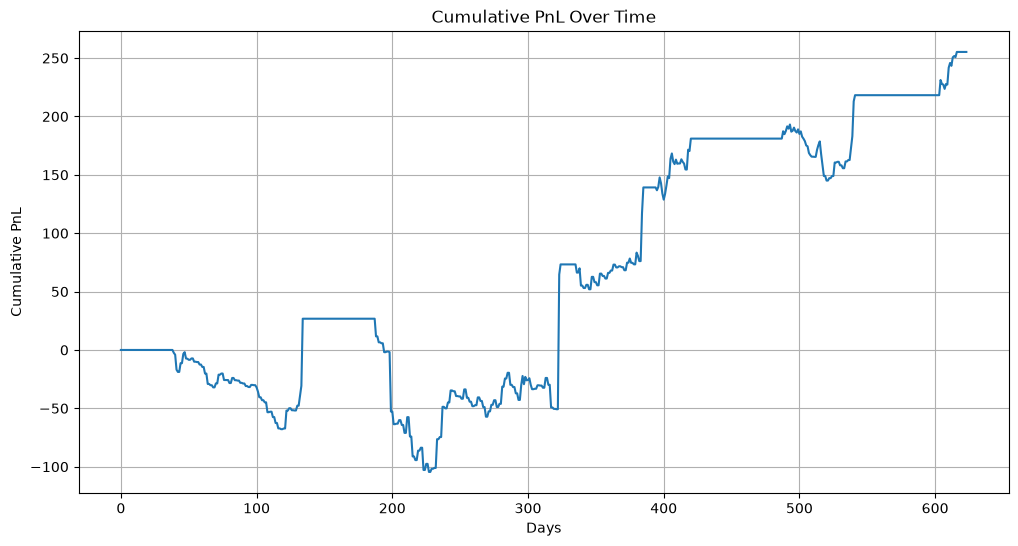

{'total_pnl': np.float64(255.26398495282388), 'sharpe_ratio': np.float64(1.4737223135081643), 'max_drawdown': np.float64(-131.25176565167635), 'n_trades': np.int64(144), 'win_rate': np.float64(0.4411764705882353)}


In [5]:
n = len(cumulative_pnl)
t = np.arange(n)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(t, cumulative_pnl)
plt.xlabel('Days')
plt.ylabel('Cumulative PnL')
plt.title('Cumulative PnL Over Time')
plt.grid(True)
plt.show()

print(stats)

In [ ]:
paires = [('TMO', 'DHR'),('UNH', 'ELV'), ('DE', 'AGCO'), ('SNPS', 'CDNS')]

for tik1, tik2 in paires :
    df = pd.concat([data[tik1], data[tik2]], axis=1).dropna()
    prixA = df.iloc[:, 0]
    prixB = df.iloc[:, 1]
    spread, hedge = Coint_verif.spread_n_hedge_ratio_static(prixA, prixB)


    # Création du spread pour le backtest

    df_bt = pd.concat([data_bt["UNH"], data_bt["ELV"]], axis=1).dropna()
    prixA_bt = df_bt.iloc[:, 0]
    prixB_bt = df_bt.iloc[:, 1]
    spread_bt = prixA_bt - hedge * prixB_bt

    # Backtest

    ou_estim = OUEstimator()
    ou_estim.fit_ols(spread)
    strat = Strategie(ou_estimator=ou_estim)
    cumulative_pnl, stats = strat.backtest(spread=np.asarray(spread_bt))

    # Plot the PnL

    n = len(cumulative_pnl)
    t = np.arange(n)

    import matplotlib.pyplot as plt

    plt.figure(figsize=(12, 6))
    plt.plot(t, cumulative_pnl)
    plt.xlabel('Days')
    plt.ylabel('Cumulative PnL')
    plt.title(f'Cumulative PnL Over Time : {tik1} - {tik2}')
    plt.grid(True)
    plt.show()


## Backtest avec un capital de 10000$ et un risque de 5% par trade sans frais de transaction

In [7]:
# 1 : Récupérer le hedge_ratio

df = pd.concat([data["UNH"], data["ELV"]], axis=1).dropna()
prixA = df.iloc[:, 0]
prixB = df.iloc[:, 1]
spread, hedge = Coint_verif.spread_n_hedge_ratio_static(prixA, prixB)


# Création des séries pour le backtest

df_bt = pd.concat([data_bt["UNH"], data_bt["ELV"]], axis=1).dropna()
prixA_bt = df_bt.iloc[:, 0]
prixB_bt = df_bt.iloc[:, 1]

# Backtest

ou_estim = OUEstimator()
ou_estim.fit_ols(spread)
strat = Strategie(ou_estimator=ou_estim)
patrimoine = strat.simulate_capital(prixA=prixA_bt, prixB=prixB_bt, hedge = hedge, f=0.5)

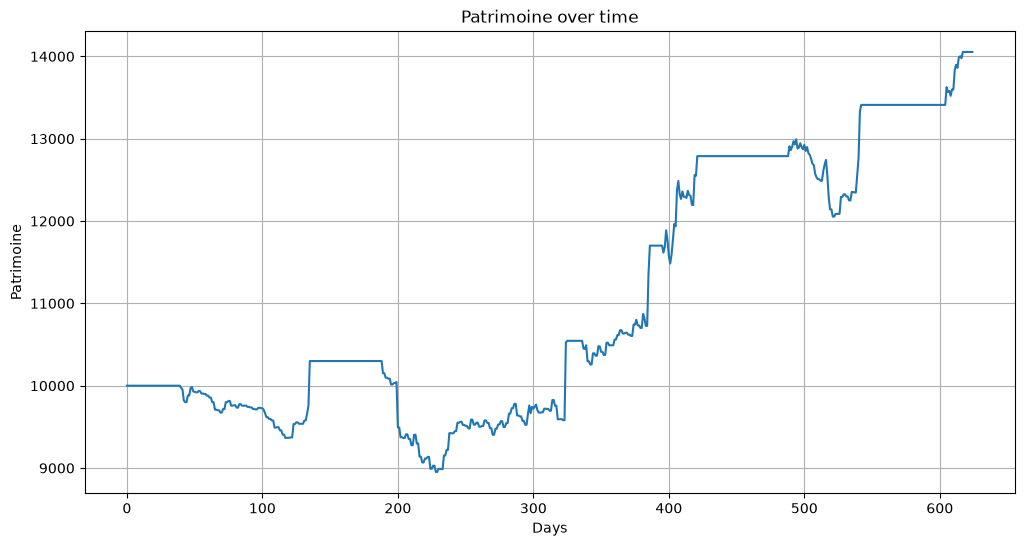

In [8]:
t = np.arange(len(prixA_bt))
plt.figure(figsize=(12, 6))
plt.plot(t[:len(patrimoine)], patrimoine)
plt.xlabel("Days")
plt.ylabel("Patrimoine")
plt.title("Patrimoine over time")
plt.grid(True)
plt.show()